In [1]:
# Task 4: Infinite Loop Detection in Software

print("=" * 60)
print("FORMAL LANGUAGE AND AUTOMATA - TASK 4")
print("Infinite Loop Detection in Software")
print("=" * 60)

print("\nObjective:")
print("To detect possible infinite loops using bounded program analysis.")

FORMAL LANGUAGE AND AUTOMATA - TASK 4
Infinite Loop Detection in Software

Objective:
To detect possible infinite loops using bounded program analysis.


In [3]:
# Define a simple program model

def run_program(start, condition, update, max_steps=1000):
    value = start
    history = []

    for step in range(max_steps):
        history.append(value)

        if not condition(value):
            return {
                "status": "TERMINATES",
                "steps": step,
                "final_value": value,
                "history": history
            }

        value = update(value)

    return {
        "status": "POSSIBLE INFINITE LOOP",
        "steps": max_steps,
        "final_value": value,
        "history": history
    }

print("Program model created successfully.")

Program model created successfully.


In [5]:
# Test Case 1: Terminating Loop

result1 = run_program(
    start=0,
    condition=lambda x: x < 10,
    update=lambda x: x + 1,
    max_steps=1000
)

print("TEST CASE 1")
print("-" * 40)
print("Status      :", result1["status"])
print("Steps       :", result1["steps"])
print("Final Value :", result1["final_value"])

TEST CASE 1
----------------------------------------
Status      : TERMINATES
Steps       : 10
Final Value : 10


In [7]:
# Test Case 2: Possible Infinite Loop

result2 = run_program(
    start=0,
    condition=lambda x: True,
    update=lambda x: x + 1,
    max_steps=1000
)

print("TEST CASE 2")
print("-" * 40)
print("Status      :", result2["status"])
print("Steps       :", result2["steps"])
print("Final Value :", result2["final_value"])

TEST CASE 2
----------------------------------------
Status      : POSSIBLE INFINITE LOOP
Steps       : 1000
Final Value : 1000


In [9]:
# Test Case 3: Decreasing Terminating Loop

result3 = run_program(
    start=10,
    condition=lambda x: x > 0,
    update=lambda x: x - 1,
    max_steps=1000
)

print("TEST CASE 3")
print("-" * 40)
print("Status      :", result3["status"])
print("Steps       :", result3["steps"])
print("Final Value :", result3["final_value"])

TEST CASE 3
----------------------------------------
Status      : TERMINATES
Steps       : 10
Final Value : 0


In [11]:
# Test Case 4: Loop with No Progress

result4 = run_program(
    start=5,
    condition=lambda x: x < 10,
    update=lambda x: x,
    max_steps=100
)

print("TEST CASE 4")
print("-" * 40)
print("Status      :", result4["status"])
print("Steps       :", result4["steps"])
print("Final Value :", result4["final_value"])

TEST CASE 4
----------------------------------------
Status      : POSSIBLE INFINITE LOOP
Steps       : 100
Final Value : 5


In [13]:
# Compare all test cases

results = [result1, result2, result3, result4]

print("=" * 60)
print("TEST CASE SUMMARY")
print("=" * 60)

for i, result in enumerate(results, start=1):
    print(f"Test Case {i}")
    print(f"Status : {result['status']}")
    print(f"Steps  : {result['steps']}")
    print()

TEST CASE SUMMARY
Test Case 1
Status : TERMINATES
Steps  : 10

Test Case 2
Status : POSSIBLE INFINITE LOOP
Steps  : 1000

Test Case 3
Status : TERMINATES
Steps  : 10

Test Case 4
Status : POSSIBLE INFINITE LOOP
Steps  : 100



In [15]:
# Bounded Infinite Loop Detection

def bounded_loop_detector(start, condition, update, max_steps=50):
    value = start
    visited = set()

    for step in range(max_steps):

        if not condition(value):
            return "TERMINATES", step, value

        # Detect repeated state
        if value in visited:
            return "LOOP DETECTED", step, value

        visited.add(value)
        value = update(value)

    return "POSSIBLE INFINITE LOOP", max_steps, value


print("Bounded loop detector created successfully.")

Bounded loop detector created successfully.


In [17]:
# Test repeated-state detection

result = bounded_loop_detector(
    start=5,
    condition=lambda x: x < 10,
    update=lambda x: x,
    max_steps=50
)

print("REPEATED STATE TEST")
print("-" * 40)
print("Status      :", result[0])
print("Steps       :", result[1])
print("Final Value :", result[2])

REPEATED STATE TEST
----------------------------------------
Status      : LOOP DETECTED
Steps       : 1
Final Value : 5


In [19]:
# Test a terminating program using bounded detection

result = bounded_loop_detector(
    start=0,
    condition=lambda x: x < 10,
    update=lambda x: x + 1,
    max_steps=50
)

print("TERMINATING PROGRAM TEST")
print("-" * 40)
print("Status      :", result[0])
print("Steps       :", result[1])
print("Final Value :", result[2])

TERMINATING PROGRAM TEST
----------------------------------------
Status      : TERMINATES
Steps       : 10
Final Value : 10


In [21]:
# Test an infinite loop using bounded detection

result = bounded_loop_detector(
    start=0,
    condition=lambda x: True,
    update=lambda x: x + 1,
    max_steps=50
)

print("INFINITE LOOP TEST")
print("-" * 40)
print("Status      :", result[0])
print("Steps       :", result[1])
print("Final Value :", result[2])

INFINITE LOOP TEST
----------------------------------------
Status      : POSSIBLE INFINITE LOOP
Steps       : 50
Final Value : 50


In [23]:
# Formal computational representation

print("=" * 60)
print("FORMAL MODEL")
print("=" * 60)

print("""
Input  : Program P and input I

Question:
Will P halt on input I?

HALT(P, I) = 1  -> Program terminates
HALT(P, I) = 0  -> Program does not terminate

General Halting Problem:
For arbitrary programs, an exact algorithm cannot decide
termination for every possible program.

Practical approach:
Use bounded execution and restricted static analysis
to detect possible infinite loops.
""")

FORMAL MODEL

Input  : Program P and input I

Question:
Will P halt on input I?

HALT(P, I) = 1  -> Program terminates
HALT(P, I) = 0  -> Program does not terminate

General Halting Problem:
For arbitrary programs, an exact algorithm cannot decide
termination for every possible program.

Practical approach:
Use bounded execution and restricted static analysis
to detect possible infinite loops.



In [25]:
# Decidability demonstration table

import pandas as pd

data = {
    "Problem": [
        "Bounded loop detection",
        "Repeated-state detection",
        "General Halting Problem"
    ],
    "Input": [
        "Program + finite step limit",
        "Program + finite execution states",
        "Any program + any input"
    ],
    "Decision": [
        "Decidable within bound",
        "Decidable within analyzed states",
        "Undecidable in general"
    ],
    "Practical Use": [
        "Testing",
        "Static / runtime analysis",
        "Theoretical limitation"
    ]
}

df = pd.DataFrame(data)

display(df)

,Problem,Input,Decision,Practical Use
0,Bounded loop detection,Program + finite step limit,Decidable within bound,Testing
1,Repeated-state detection,Program + finite execution states,Decidable within analyzed states,Static / runtime analysis
2,General Halting Problem,Any program + any input,Undecidable in general,Theoretical limitation


In [27]:
# Worked example

print("=" * 60)
print("WORKED EXAMPLE")
print("=" * 60)

print("""
Program:

x = 0
while x < 5:
    x = x + 1

Execution:

x = 0
x = 1
x = 2
x = 3
x = 4
x = 5

At x = 5, the condition x < 5 becomes false.

Therefore:
The program terminates.
""")

WORKED EXAMPLE

Program:

x = 0
while x < 5:
    x = x + 1

Execution:

x = 0
x = 1
x = 2
x = 3
x = 4
x = 5

At x = 5, the condition x < 5 becomes false.

Therefore:
The program terminates.



In [29]:
# Infinite loop worked example

print("=" * 60)
print("INFINITE LOOP EXAMPLE")
print("=" * 60)

print("""
Program:

x = 0
while True:
    x = x + 1

The condition is always True.

Therefore:
The loop does not reach a terminating condition.

In practical bounded analysis:
The program is reported as a POSSIBLE INFINITE LOOP
after the specified maximum number of steps.
""")

INFINITE LOOP EXAMPLE

Program:

x = 0
while True:
    x = x + 1

The condition is always True.

Therefore:
The loop does not reach a terminating condition.

In practical bounded analysis:
The program is reported as a POSSIBLE INFINITE LOOP
after the specified maximum number of steps.



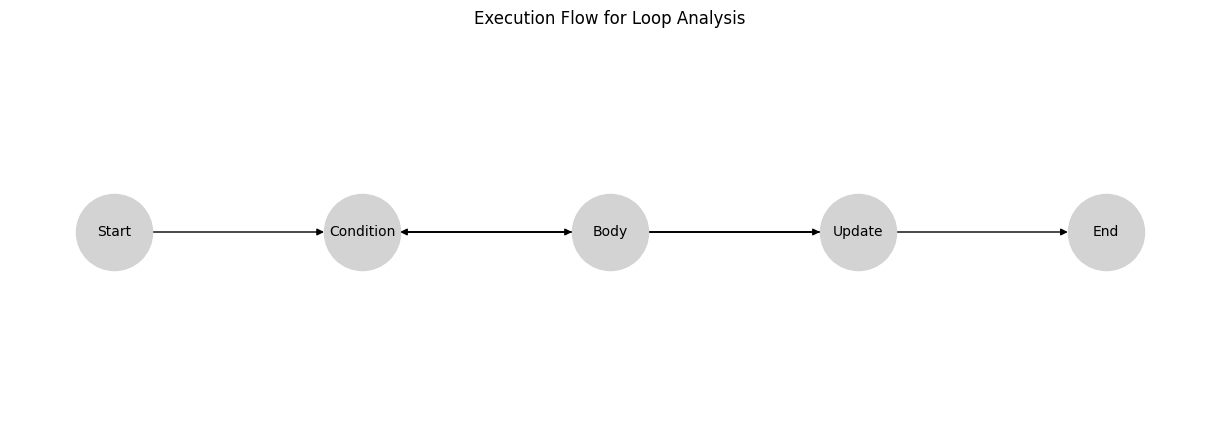

In [31]:
# Generate execution graph

import matplotlib.pyplot as plt
import networkx as nx

G = nx.DiGraph()

nodes = ["Start", "Condition", "Body", "Update", "End"]

G.add_edges_from([
    ("Start", "Condition"),
    ("Condition", "Body"),
    ("Body", "Update"),
    ("Update", "Condition"),
    ("Condition", "End")
])

pos = {
    "Start": (0, 1),
    "Condition": (1, 1),
    "Body": (2, 1),
    "Update": (3, 1),
    "End": (4, 1)
}

plt.figure(figsize=(12, 4))

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=3000,
    node_color="lightgray",
    font_size=10,
    arrows=True
)

plt.title("Execution Flow for Loop Analysis")
plt.axis("off")
plt.show()

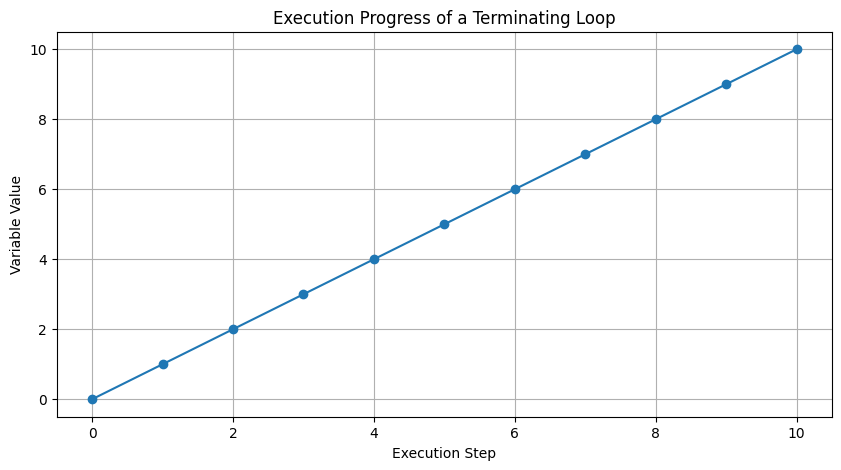

In [33]:
# Execution history graph

import matplotlib.pyplot as plt

history = result1["history"]

plt.figure(figsize=(10, 5))

plt.plot(
    range(len(history)),
    history,
    marker="o"
)

plt.xlabel("Execution Step")
plt.ylabel("Variable Value")
plt.title("Execution Progress of a Terminating Loop")
plt.grid(True)

plt.show()

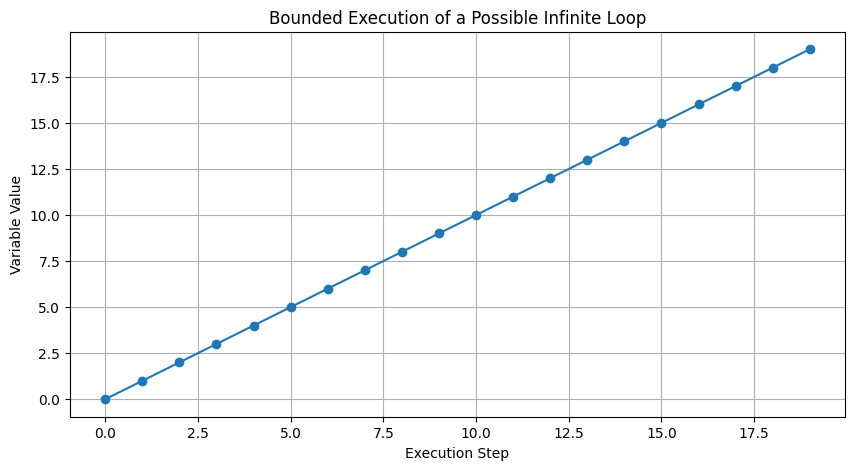

In [35]:
# Infinite loop bounded execution graph

infinite_result = run_program(
    start=0,
    condition=lambda x: True,
    update=lambda x: x + 1,
    max_steps=20
)

history = infinite_result["history"]

plt.figure(figsize=(10, 5))

plt.plot(
    range(len(history)),
    history,
    marker="o"
)

plt.xlabel("Execution Step")
plt.ylabel("Variable Value")
plt.title("Bounded Execution of a Possible Infinite Loop")
plt.grid(True)

plt.show()

In [37]:
# Final validation table

validation_data = {
    "Test Case": [
        "Finite increasing loop",
        "Always true loop",
        "Finite decreasing loop",
        "No-progress loop"
    ],
    "Expected Behaviour": [
        "Terminate",
        "Infinite",
        "Terminate",
        "Infinite"
    ],
    "Detected Result": [
        result1["status"],
        result2["status"],
        result3["status"],
        result4["status"]
    ]
}

validation_df = pd.DataFrame(validation_data)

display(validation_df)

,Test Case,Expected Behaviour,Detected Result
0,Finite increasing loop,Terminate,TERMINATES
1,Always true loop,Infinite,POSSIBLE INFINITE LOOP
2,Finite decreasing loop,Terminate,TERMINATES
3,No-progress loop,Infinite,POSSIBLE INFINITE LOOP


In [38]:
# Final conclusion output

print("=" * 60)
print("TASK 4 COMPUTATIONAL ANALYSIS COMPLETED")
print("=" * 60)

print("""
Problem:
Infinite Loop Detection in Software

Formal Concept:
Halting Problem and Computability

General Case:
Undecidable

Practical Case:
Bounded execution and restricted-state analysis

Validation:
Multiple terminating and non-terminating loop examples
were tested successfully.
""")

TASK 4 COMPUTATIONAL ANALYSIS COMPLETED

Problem:
Infinite Loop Detection in Software

Formal Concept:
Halting Problem and Computability

General Case:
Undecidable

Practical Case:
Bounded execution and restricted-state analysis

Validation:
Multiple terminating and non-terminating loop examples
were tested successfully.

